# Python Data Cleaning and Visualization - 10/17/2026 - lucjus5243

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Airbnb dataset
df = pd.read_excel("AirBnBSummary_v2.xlsx")

# Display dataset information
print("Original Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Original Dataset Shape: (1779, 10)

Column Names:
['id', 'host_id', 'host_name', 'neighbourhood', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'availability_365', '<StudentID>']

First 5 Rows:


,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,NaN
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,NaN
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,NaN
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,NaN
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,NaN


In [3]:

# Step 5 - Remove duplicate entries

# Count duplicate rows
duplicates = df.duplicated().sum()
print("Duplicate rows before cleaning:", duplicates)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Display results
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Dataset shape after removing duplicates:", df.shape)

display(df.head())


Duplicate rows before cleaning: 4
Duplicate rows after cleaning: 0
Dataset shape after removing duplicates: (1775, 10)


,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,NaN
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,NaN
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,NaN
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,NaN
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,NaN


In [4]:

# Step 6 - Correct capitalization

# Count incorrect entries before cleaning
incorrect_count = (df["room_type"] == "Private room").sum()
print("Private room entries before correction:", incorrect_count)

# Correct capitalization
df["room_type"] = df["room_type"].replace("Private room", "Private Room")

# Verify the correction
remaining = (df["room_type"] == "Private room").sum()
print("Private room entries after correction:", remaining)

print("\nUpdated room types:")
print(df["room_type"].value_counts())


Private room entries before correction: 240
Private room entries after correction: 0

Updated room types:
room_type
Entire home/apt    1535
Private Room        240
Name: count, dtype: int64


In [5]:

# Step 7 - Fill missing values using the median

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numerical values with the median
numeric_columns = df.select_dtypes(include=[np.number]).columns

for column in numeric_columns:
    if df[column].isnull().any():
        median_value = df[column].median()
        df[column] = df[column].fillna(median_value)
        print(f"Filled {column} with median: {median_value}")

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
id                      0
host_id                 0
host_name               0
neighbourhood           0
room_type               0
price                   4
minimum_nights          0
number_of_reviews       0
availability_365        5
<StudentID>          1775
dtype: int64
Filled price with median: 115.0
Filled availability_365 with median: 178.0
Filled <StudentID> with median: nan

Missing values after cleaning:
id                      0
host_id                 0
host_name               0
neighbourhood           0
room_type               0
price                   0
minimum_nights          0
number_of_reviews       0
availability_365        0
<StudentID>          1775
dtype: int64


In [6]:

# Fill the Student ID column
df["<StudentID>"] = "lucjus5243"

# Verify missing values
print("Missing values after final cleaning:")
print(df.isnull().sum())

# Display updated dataset
display(df.head())

Missing values after final cleaning:
id                   0
host_id              0
host_name            0
neighbourhood        0
room_type            0
price                0
minimum_nights       0
number_of_reviews    0
availability_365     0
<StudentID>          0
dtype: int64


,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
0,7909479,41706311,David,Downtown,Entire home/apt,107.0,30,27,365.0,lucjus5243
1,15966488,103700433,Erin,Downtown,Entire home/apt,100.0,1,250,74.0,lucjus5243
2,19859814,103700433,Erin,Downtown,Entire home/apt,100.0,1,309,79.0,lucjus5243
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,lucjus5243
4,21712505,103700433,Erin,Downtown,Entire home/apt,100.0,1,178,68.0,lucjus5243


In [7]:

# Step 9 - Remove outliers using IQR

print("Rows before removing outliers:", len(df))

# Columns to check for outliers
columns = ["price", "minimum_nights",
           "number_of_reviews", "availability_365"]

# Calculate IQR boundaries
Q1 = df[columns].quantile(0.25)
Q3 = df[columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Keep rows within the IQR boundaries
outliers = ((df[columns] < lower_bound) |
            (df[columns] > upper_bound)).any(axis=1)

df = df.loc[~outliers].copy()

print("Outliers removed:", outliers.sum())
print("Rows after removing outliers:", len(df))

display(df.head())


Rows before removing outliers: 1775
Outliers removed: 570
Rows after removing outliers: 1205


,id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
3,21071138,22992627,Joseph,Downtown,Entire home/apt,100.0,2,144,338.0,lucjus5243
6,28577094,211013898,Megan,Downtown,Entire home/apt,231.0,2,88,231.0,lucjus5243
7,35321049,22992627,Joseph,Downtown,Entire home/apt,112.0,2,89,219.0,lucjus5243
8,36728950,4965048,Mathew,Downtown,Entire home/apt,125.0,1,77,323.0,lucjus5243
9,37928558,116400313,Nate,Downtown,Entire home/apt,112.0,2,88,60.0,lucjus5243


In [8]:

# Step 10 - Save cleaned dataset to Excel

file_name = "AirBnBSummary_v2_Python_Cleaned.xlsx"

df.to_excel(file_name, index=False)

print("Cleaned dataset saved successfully!")
print("File name:", file_name)
print("Total cleaned listings:", len(df))


Cleaned dataset saved successfully!
File name: AirBnBSummary_v2_Python_Cleaned.xlsx
Total cleaned listings: 1205


In [9]:

# Step 11 - Descriptive Statistics

print("AIRBNB DESCRIPTIVE STATISTICS")
print("-----------------------------")

print("1. Total listings:", len(df))

print("2. Minimum price:", df["price"].min())

print("3. Maximum price:", df["price"].max())

print("4. Mean price:", round(df["price"].mean(), 2))

print("5. Median number of reviews:",
      df["number_of_reviews"].median())

print("6. Mode of minimum nights:",
      df["minimum_nights"].mode()[0])

print("7. Standard deviation of price:",
      round(df["price"].std(), 2))

print("8. Correlation between price and availability_365:",
      round(df["price"].corr(df["availability_365"]), 4))


AIRBNB DESCRIPTIVE STATISTICS
-----------------------------
1. Total listings: 1205
2. Minimum price: 32.0
3. Maximum price: 308.0
4. Mean price: 132.18
5. Median number of reviews: 20.0
6. Mode of minimum nights: 1
7. Standard deviation of price: 62.53
8. Correlation between price and availability_365: 0.0928


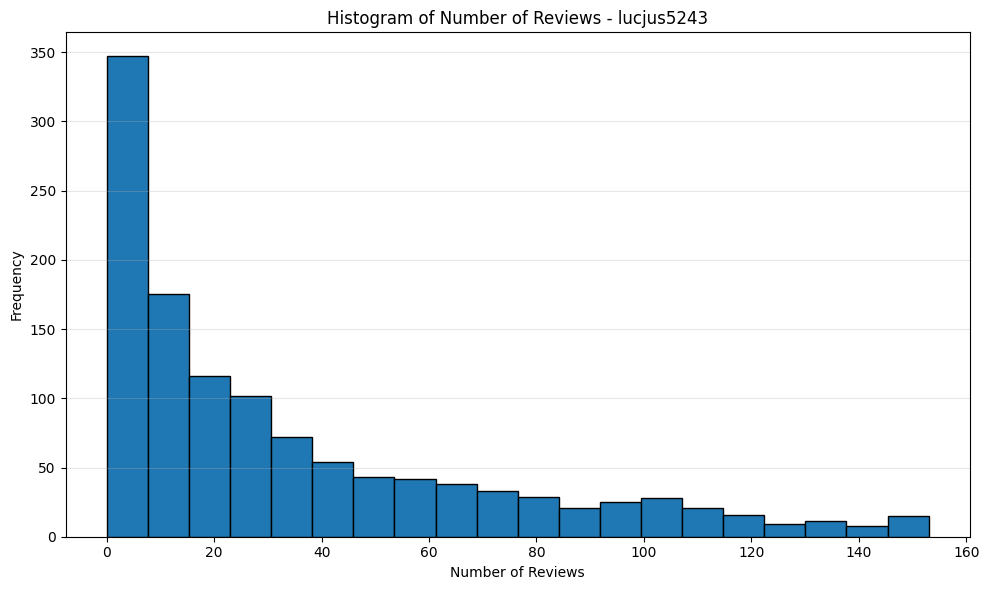

In [10]:

# Step 12 - Histogram of number_of_reviews

plt.figure(figsize=(10, 6))

plt.hist(df["number_of_reviews"],
         bins=20, edgecolor="black")

plt.title("Histogram of Number of Reviews - lucjus5243")
plt.xlabel("Number of Reviews")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


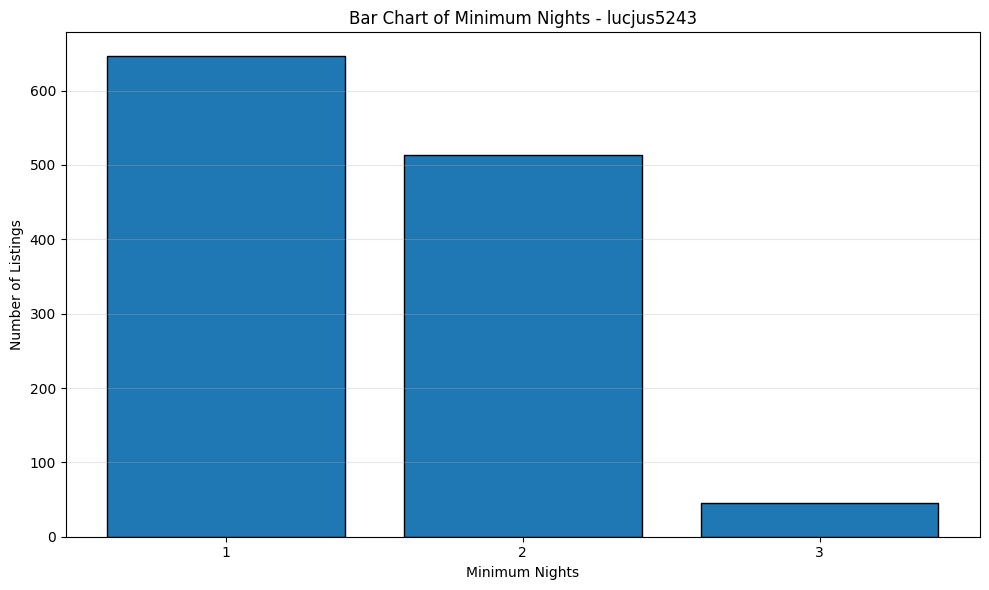

In [11]:

# Step 13 - Bar Chart of minimum_nights

# Count listings for each minimum-night requirement
night_counts = df["minimum_nights"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

plt.bar(night_counts.index.astype(str),
        night_counts.values,
        edgecolor="black")

plt.title("Bar Chart of Minimum Nights - lucjus5243")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


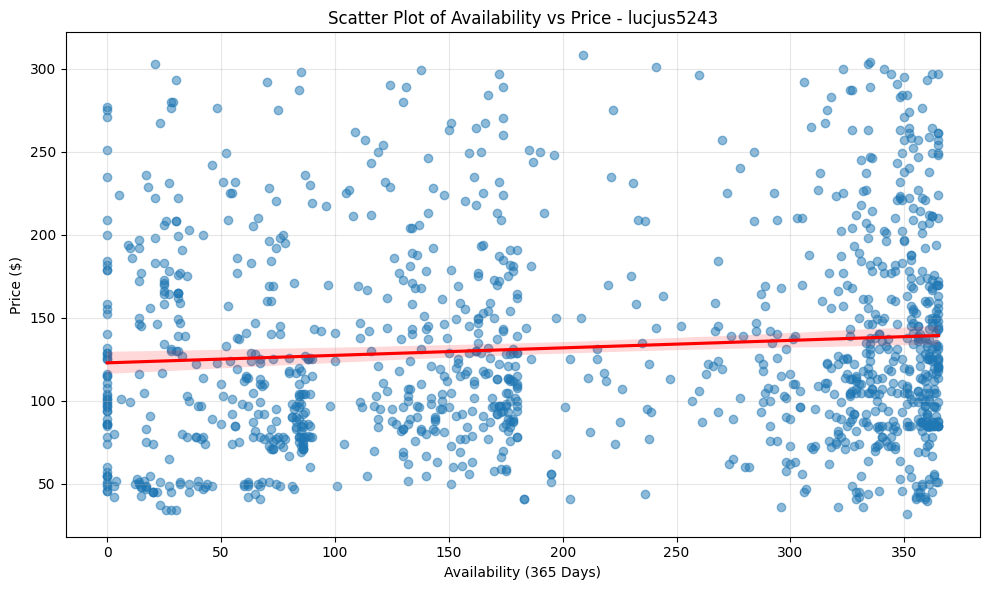

In [12]:

# Step 14 - Scatter Plot of Availability

plt.figure(figsize=(10, 6))

# Scatter plot
sns.regplot(
    data=df,
    x="availability_365",
    y="price",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Scatter Plot of Availability vs Price - lucjus5243")
plt.xlabel("Availability (365 Days)")
plt.ylabel("Price ($)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


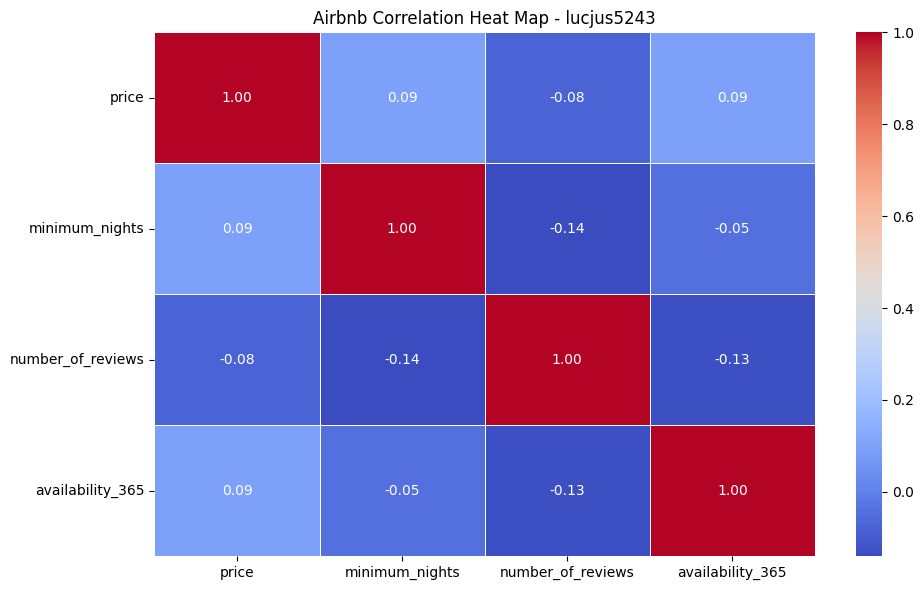

In [13]:

# Step 15 - Correlation Heat Map

columns = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "availability_365"
]

correlation_matrix = df[columns].corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Airbnb Correlation Heat Map - lucjus5243")
plt.tight_layout()
plt.show()
